# Modelo híbrido: votación + regla del conector decisivo

En las reseñas mixtas cuya última opinión va después de un conector conclusivo o de contraste ("al final", "aun así", "pero", ...), la etiqueta coincide casi siempre con la polaridad de esa opinión. En ese grupo la regla acierta más que el clasificador de votación, así que aquí se usa la regla cuando aplica y el clasificador en el resto.

Los conectores decisivos se eligen solo con el conjunto de entrenamiento, para no filtrar información del test.

In [2]:
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from imblearn.pipeline import Pipeline
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import VotingClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import SVC

nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

True

In [3]:
data = pd.read_csv("data/train.csv")

X = data.drop("label", axis=1)
y = data["label"]

# Mismo split que model_training.ipynb
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")

Train: 9600 | Test: 2400


## Preprocesamiento

Las mismas funciones de `model_training.ipynb`: normalización sin tildes, stopwords, marcado de negación, stemming y el preprocesador con las columnas de última oración y oración posterior al contraste.

In [4]:
import unicodedata


def quitar_tildes(text):
    """Elimina tildes y diéresis, pues muchas reseñas están escritas sin ellas."""
    return unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")


spanish_stopwords_completas = set(stopwords.words("spanish"))

palabras_negativas = {
    "no",
    "nunca",
    "jamás",
    "nadie",
    "ninguno",
    "poco",
    "ni",
    "pero",
    "sin",
    "muy",
    "más",
    "mucho",
    "nada",
    "contra",
    "algo",
}

# Se comparan sin tildes porque el texto también se normaliza sin tildes
spanish_stopwords = {
    quitar_tildes(w) for w in spanish_stopwords_completas - palabras_negativas
}

# Lista mínima (artículos, preposiciones y pronombres) para no romper frases hechas como "con los ojos cerrados"
stopwords_minimas = {
    quitar_tildes(w)
    for w in [
        "el",
        "la",
        "los",
        "las",
        "un",
        "una",
        "unos",
        "unas",
        "de",
        "del",
        "al",
        "y",
        "o",
        "e",
        "a",
        "en",
        "que",
        "lo",
        "le",
        "les",
        "se",
        "me",
        "mi",
        "mis",
        "su",
        "sus",
    ]
}

print(f"Cantidad de stopwords en español: {len(spanish_stopwords)}")
print(f"Contiene no: {'no' in spanish_stopwords}")

Cantidad de stopwords en español: 295
Contiene no: False


In [5]:
stemmer = SnowballStemmer("spanish")

# Palabras que niegan lo que viene después de ellas (sin tildes, como el texto normalizado)
NEGADORES = {
    "no",
    "nunca",
    "jamas",
    "ni",
    "nada",
    "sin",
    "tampoco",
    "nadie",
    "ninguno",
    "ninguna",
}
# Tokens que cierran el alcance de una negación: puntuación y conectores adversativos
FIN_NEGACION = {".", ",", ";", ":", "!", "?", "pero", "aunque", "sino"}
NEG_PREFIX = "NEG_"


def marcar_negacion(tokens):
    """Agrega el prefijo NEG_ a las palabras dentro del alcance de una negación, es decir,
    desde el negador hasta el siguiente signo de puntuación o conector adversativo."""
    marcados, negando = [], False
    for t in tokens:
        if t in FIN_NEGACION:
            negando = False
        elif t in NEGADORES:
            negando = True
        elif negando:
            t = NEG_PREFIX + t
        marcados.append(t)
    return marcados


def tokenizer_stemmer(text, stopwords=spanish_stopwords, stemming=True):
    """Hacemos el preprocesamiento del texto: normalización, tokenización, marcado de negación y stemming en una sola función para luego pasarlo al pipeline de procesamiento."""
    tokens = marcar_negacion(word_tokenize(quitar_tildes(text.lower())))
    resultado = []
    for t in tokens:
        palabra = t.removeprefix(NEG_PREFIX)
        if palabra.isalpha() and palabra not in stopwords:
            prefijo = NEG_PREFIX if t.startswith(NEG_PREFIX) else ""
            resultado.append(prefijo + (stemmer.stem(palabra) if stemming else palabra))
    return resultado

In [6]:
import re
from collections import Counter, defaultdict
from functools import partial

TEXT_COLUMN = "text"
COLUMN_LAST_SENTENCE = "last_sentence"
COLUMN_CONTRAST = "after_contrast"
TARGET_COLUMN = "label"

VECTORIZERS = {
    "count": CountVectorizer,
    "tfidf": TfidfVectorizer,
}


def extract_last_sentences(text, n_sentences):
    """Extrae las últimas n_sentences oraciones no vacías de un texto."""
    sentences = [s.strip() for s in text.split(".") if s.strip()]
    return ". ".join(sentences[-n_sentences:]) if sentences else ""


def add_last_sentences(X, n_sentences=1):
    """Agrega la columna con la última oración del texto, conservando las columnas originales."""
    return X.assign(
        **{
            COLUMN_LAST_SENTENCE: X[TEXT_COLUMN].apply(
                lambda x: extract_last_sentences(x, n_sentences)
            )
        }
    )


# Conectores tras los cuales suele estar la opinión que define la reseña: "La pantalla es mala. Eso sí, la batería es excelente".
# "por otro lado", "en cambio" y "en general" no se incluyen porque la cláusula que sigue no predice mejor la etiqueta que la anterior.
CONECTORES_CONTRASTE = [
    "pero",
    "sin embargo",
    "aunque",
    "no obstante",
    "aun asi",
    "con todo",
    "lo que si",
    "a fin de cuentas",
    "al final"
]
PATRON_CONTRASTE = re.compile(r"\b(?:" + "|".join(CONECTORES_CONTRASTE) + r")\b")


def extract_after_contrast(text):
    """Extrae la oración que sigue al último conector de contraste, o una cadena vacía si no hay ninguno."""
    normalizado = quitar_tildes(text.lower())
    coincidencias = list(PATRON_CONTRASTE.finditer(normalizado))
    if not coincidencias:
        return ""
    return normalizado[coincidencias[-1].end() :].split(".")[0].strip(" ,")


def add_after_contrast(X):
    """Agrega la columna con la oración posterior al último conector de contraste, conservando las columnas originales."""
    return X.assign(**{COLUMN_CONTRAST: X[TEXT_COLUMN].apply(extract_after_contrast)})


def remove_first_sentence(X):
    """Elimina la primera oración del texto, conservando las columnas originales."""

    def first_sentence_removed(text):
        sentences = [s.strip() for s in text.split(".") if s.strip()]
        return ". ".join(sentences[1:]) if len(sentences) > 1 else ""

    return X.assign(**{TEXT_COLUMN: X[TEXT_COLUMN].apply(first_sentence_removed)})


def split_sentences(text):
    """Divide el texto en oraciones no vacías."""
    return [s.strip() for s in text.split(".") if s.strip()]


def normalize_sentence(sentence):
    """Normaliza una oración para compararla con otras: minúsculas, sin tildes y sin comas en los extremos."""
    return quitar_tildes(sentence.lower()).strip(" ,")




def vectorizer_function(
    vectorizer="count",
    ngram_range=(1, 3),
    stopwords=spanish_stopwords,
    stemming=True,
    sublinear_tf=False,
    min_df=1,
):
    """Vectorizador de palabras con el tokenizador propio. sublinear_tf (1 + log(tf)) solo existe en TF-IDF,
    por eso se pasa únicamente a TfidfVectorizer."""
    tfidf_kwargs = {"sublinear_tf": sublinear_tf} if vectorizer == "tfidf" else {}
    return VECTORIZERS[vectorizer](
        tokenizer=partial(tokenizer_stemmer, stopwords=stopwords, stemming=stemming),
        token_pattern=None,
        ngram_range=ngram_range,
        min_df=min_df,
        **tfidf_kwargs,
    )




def build_preprocessor(
    vectorizer="count",
    ngram_range=(1, 3),
    stopwords=spanish_stopwords,
    stemming=True,
    sublinear_tf=False,
    min_df=1,
):
    """Construye el preprocesador de las features con el vectorizador indicado: 'count' o 'tfidf'.

    1. Crea la columna con la última oración y la columna con la oración posterior al último conector de contraste.
    2. Opcionalmente elimina la primera oración del texto completo (por defecto no la elimina;
       en el grid search se prueba con FunctionTransfomer(remove_first_sentence)).
    3. Vectoriza por separado el texto completo, la última oración y la oración posterior al contraste.
       ngram_range, stopwords, sublinear_tf y min_df controlan los tres vectorizadores de palabras.
    """
    word_vectorizer = partial(
        vectorizer_function, vectorizer, ngram_range, stopwords, stemming, sublinear_tf, min_df
    )
    vectorizers = [
        ("text_vectorizer", word_vectorizer(), TEXT_COLUMN,),
        ("last_sentence_vectorizer", word_vectorizer(), COLUMN_LAST_SENTENCE),
        ("contrast_vectorizer", word_vectorizer(), COLUMN_CONTRAST),
    ]
    steps = []
    return Pipeline(
        steps
        + [
            (
                "last_sentence",
                FunctionTransformer(add_last_sentences, kw_args={"n_sentences": 1}),
            ),
            ("after_contrast", FunctionTransformer(add_after_contrast)),
            ("remove_first_sentence", FunctionTransformer(remove_first_sentence)),
            ("vectorizers", ColumnTransformer(vectorizers)),
        ]
    )

## Extracción de opiniones

Igual que en la sección "Análisis de las oraciones" de `model_training.ipynb`: cada opinión es una cláusula que menciona un aspecto del producto con una frase o adjetivo de opinión, junto con el conector que la introduce.

In [7]:
import re

# Vocabulario del generador de reseñas: aspectos del producto y frases de opinión fijas
ASPECTOS = [
    "duracion de la bateria", "atencion al cliente", "resistencia al agua", "nitidez de la imagen", "manual de uso",
    "boton de encendido", "sistema de sonido", "sistema de carga", "app del fabricante", "menu de ajustes",
    "relacion calidad-precio", "relacion calidad precio", "calidad de sonido", "calidad de imagen", "cable de carga",
    "calidad de construccion", "calidad del sonido", "pantalla", "empaque", "precio", "cargador", "instalacion",
    "tamano", "control", "acabado", "bateria", "construccion", "correa", "autonomia", "procesador", "resolucion",
    "peso", "portabilidad", "camara", "senal", "ensamblaje", "velocidad", "ventilador", "sonido", "aplicacion",
    "motor", "material", "microfono", "conexion", "rendimiento", "teclado", "soporte", "carcasa", "funda",
    "terminacion", "tapa", "memoria", "comodidad", "ergonomia", "cable", "interfaz", "diseno", "color", "calidad",
]
PATRON_ASPECTO = re.compile(r"\b(" + "|".join(sorted(map(re.escape, ASPECTOS), key=len, reverse=True)) + r")\b")

FRASES_NEGATIVAS = [
    "no vale lo que cuesta", "me decepciono", "por debajo de la media", "se queda muy corto", "se queda corto",
    "se dano antes", "no es para nada lo que esperaba", "defraudo todas mis expectativas", "tire el dinero",
    "funciona bastante mal", "dolor de cabeza", "me arrepiento", "no le recomiendo", "error de compra",
    "quede muy molesto", "no volveria a comprar", "una estrella", "no pare de tener problemas", "arrepentido",
    "termine harto",
]
FRASES_POSITIVAS = [
    "justo lo que estaba buscando", "vale totalmente la pena", "fue todo un acierto", "me encanto",
    "funciona de maravilla", "respondio tal como esperaba", "supero todas mis expectativas", "cumple de sobra",
    "por encima de la media", "me alegra haber elegido", "me sorprendio para bien", "me hizo la vida mas facil",
    "termine feliz", "estoy feliz", "quede encantado", "con los ojos cerrados", "volveria a comprar",
    "ni una sola queja", "cinco estrellas",
]


# Adjetivos de la plantilla "<aspecto> es/resultó/me salió <adjetivo>"
ADJETIVOS_POSITIVOS = [
    "funcional", "resistente", "impecable", "sobresaliente", "veloz", "confiable", "excelente", "eficiente",
    "formidable", "fiable", "potente", "superior", "decente", "notable", "espectacular", "durable", "practica",
    "practico", "cumplidor", "cumplidora", "agradable", "comodisima", "comodisimo", "buenisima", "buenisimo",
    "rapidisima", "rapidisimo", "comoda", "comodo", "optimo", "optima", "correcta", "correcto", "solida", "solido",
    "redonda", "redondo", "ligera", "ligero", "completa", "completo", "robusta", "robusto", "buena", "bueno",
    "nitida", "nitido", "precisa", "preciso", "estupenda", "estupendo", "bien hecha", "bien hecho", "bien logrado",
    "bien lograda", "bien construida", "bien construido",
]
ADJETIVOS_NEGATIVOS = [
    "torpe", "pobre", "terrible", "decepcionante", "endeble", "debil", "desagradable", "fragil", "corriente",
    "inestable", "deficiente", "mediocre", "inconsistente", "olvidable", "incumplidor", "incumplidora", "ruidosa",
    "ruidoso", "imprecisa", "impreciso", "delicada", "delicado", "lentisima", "lentisimo", "pesima", "pesimo",
    "malisima", "malisimo", "flojo", "floja", "ordinaria", "ordinario", "aparatoso", "aparatosa", "chapucera",
    "chapucero", "basica", "basico", "incomoda", "incomodo", "limitado", "limitada", "defectuosa", "defectuoso",
    "mal terminada", "mal terminado", "mal construida", "mal construido", "mal hecha", "mal hecho",
]
PATRON_ADJ_POSITIVO = re.compile(r"\b(?:" + "|".join(ADJETIVOS_POSITIVOS) + r")\b")
PATRON_ADJ_NEGATIVO = re.compile(r"\b(?:" + "|".join(ADJETIVOS_NEGATIVOS) + r")\b")


def polaridad_clausula(clausula):
    """+1, -1 o 0. Primero busca las frases fijas (las negativas antes, por "no volveria a comprar")
    y si no hay ninguna, compara cuántos adjetivos positivos y negativos tiene."""
    if any(f in clausula for f in FRASES_NEGATIVAS):
        return -1
    if any(f in clausula for f in FRASES_POSITIVAS):
        return 1
    puntaje = len(PATRON_ADJ_POSITIVO.findall(clausula)) - len(PATRON_ADJ_NEGATIVO.findall(clausula))
    return int(np.sign(puntaje))

CONECTORES = sorted(
    ["sin embargo", "eso si", "aun asi", "lo que si", "no obstante", "a fin de cuentas", "al final", "con todo",
     "por otro lado", "por cierto", "de paso", "ademas", "ahora", "pero", "aunque", "y", "la verdad"],
    key=len, reverse=True,
)
SEPARADOR_CLAUSULAS = re.compile(
    r"([.;!?]|,?\s\b(?:pero|aunque|sin embargo|eso si|aun asi|lo que si|no obstante|y)\b)"
)


def extraer_opiniones(texto):
    """Lista de (aspecto, polaridad, conector) de cada cláusula que menciona un aspecto con una opinión.
    El conector es el que aparece justo antes o al inicio de la cláusula ("" si no hay)."""
    partes = SEPARADOR_CLAUSULAS.split(quitar_tildes(texto.lower()))
    opiniones, separador = [], ""
    for i in range(0, len(partes), 2):
        clausula = partes[i].strip(" ,")
        aspectos = PATRON_ASPECTO.findall(clausula)
        polaridad = polaridad_clausula(clausula) if aspectos else 0
        if polaridad:
            contexto = separador + " " + clausula[:30]
            conector = next((c for c in CONECTORES if re.search(rf"\b{c}\b", contexto)), "")
            opiniones.append((aspectos[0], polaridad, conector))
        separador = partes[i + 1] if i + 1 < len(partes) else ""
    return opiniones


extraer_opiniones(
    "Me decepcionó el ensamblaje de principio a fin. Al final, la tapa cumple de sobra."
)

[('ensamblaje', -1, ''), ('tapa', 1, 'al final')]

## Regla del conector decisivo

Para cada conector que introduce la última opinión de una reseña, se mide en **train** con qué frecuencia la etiqueta coincide con la polaridad de esa opinión. Se consideran decisivos los conectores con al menos 30 reseñas y una precisión de al menos 98 %. El cálculo incluye las reseñas neutrales, así que la precisión ya descuenta los casos en que la regla etiquetaría mal una reseña neutral.

In [8]:
PRECISION_MINIMA = 0.98
RESENAS_MINIMAS = 30


def ultima_opinion(texto):
    """(aspecto, polaridad, conector) de la última opinión de la reseña, o None si no tiene opiniones."""
    opiniones = extraer_opiniones(texto)
    return opiniones[-1] if opiniones else None


def polaridad_a_etiqueta(polaridad):
    return "positivo" if polaridad > 0 else "negativo"


ultimas_train = X_train["text"].apply(ultima_opinion)
con_opinion = ultimas_train.notna()
regla_train = pd.DataFrame(
    {
        "conector": ultimas_train[con_opinion].map(lambda o: o[2] or "(ninguno)"),
        "acierta": ultimas_train[con_opinion].map(lambda o: polaridad_a_etiqueta(o[1])) == y_train[con_opinion],
    }
)
precision_por_conector = (
    regla_train.groupby("conector")["acierta"]
    .agg(resenas="size", precision="mean")
    .sort_values("precision", ascending=False)
)
CONECTORES_DECISIVOS = set(
    precision_por_conector.query("resenas >= @RESENAS_MINIMAS and precision >= @PRECISION_MINIMA").index
)
print(f"Conectores decisivos: {sorted(CONECTORES_DECISIVOS)}")
precision_por_conector.round(3)

Conectores decisivos: ['a fin de cuentas', 'al final', 'aun asi', 'con todo', 'sin embargo']


,resenas,precision
conector,,
a fin de cuentas,173,1.000
al final,609,0.989
sin embargo,85,0.988
aun asi,492,0.988
con todo,280,0.982
pero,232,0.948
aunque,41,0.902
lo que si,58,0.897
la verdad,327,0.850


In [9]:
def predecir_con_regla(textos):
    """Etiqueta de la última opinión cuando va después de un conector decisivo; None donde la regla no aplica."""

    def regla(texto):
        opinion = ultima_opinion(texto)
        if opinion is not None and opinion[2] in CONECTORES_DECISIVOS:
            return polaridad_a_etiqueta(opinion[1])
        return None

    return textos.apply(regla)


regla_en_train = predecir_con_regla(X_train["text"])
aplica = regla_en_train.notna()
print(f"La regla aplica a {aplica.mean():.1%} de train, con accuracy {np.mean(regla_en_train[aplica] == y_train[aplica]):.4f}")

La regla aplica a 17.1% de train, con accuracy 0.9884


## Clasificador de votación

El mismo clasificador de votación de `model_training.ipynb` (SVC sigmoide, SVC lineal y Naive Bayes, voto `soft`). Los tres votantes se entrenan en paralelo.

In [10]:
preprocessor = build_preprocessor("tfidf")
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)
# ColumnTransformer deja los índices de la matriz dispersa desordenados y libsvm los ordena en el lugar. Con n_jobs=-1
# joblib comparte la matriz como solo lectura y SVC falla ("WRITEBACKIFCOPY base is read-only"), así que se ordenan aquí.
X_train_transformed.sort_indices()
X_test_transformed.sort_indices()
print(f"X - Train: {X_train_transformed.shape} | Test: {X_test_transformed.shape}")

voting_classifier = VotingClassifier(
    estimators=[
        ("svc_sigmoid", SVC(kernel="sigmoid", C=1.0, probability=True, random_state=42)),
        ("svc_linear", SVC(kernel="linear", C=1.0, probability=True, random_state=42)),
        ("nb", MultinomialNB()),
    ],
    voting="soft",
    n_jobs=-1,
)
voting_classifier.fit(X_train_transformed, y_train)
y_pred_voting = voting_classifier.predict(X_test_transformed)
print(f"Accuracy Voting Classifier: {accuracy_score(y_test, y_pred_voting):.4f}")

X - Train: (9600, 199644) | Test: (2400, 199644)


/Users/pedropablosanintrujillo/GitHub/proyecto-ml/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/pedropablosanintrujillo/GitHub/proyecto-ml/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy Voting Classifier: 0.9008


## Modelo híbrido

Donde la regla aplica se usa su etiqueta; en el resto, la del clasificador de votación.

La regla aplica a 409 reseñas del test (17.0%)
  En ellas: accuracy del modelo 0.9853 | accuracy de la regla 0.9804
  Predicciones que cambian: 12

Accuracy Voting Classifier: 0.9008
Accuracy modelo híbrido:    0.9000
              precision    recall  f1-score   support

    negativo       0.85      0.88      0.87       843
     neutral       0.98      0.99      0.99       715
    positivo       0.88      0.84      0.86       842

    accuracy                           0.90      2400
   macro avg       0.90      0.90      0.90      2400
weighted avg       0.90      0.90      0.90      2400



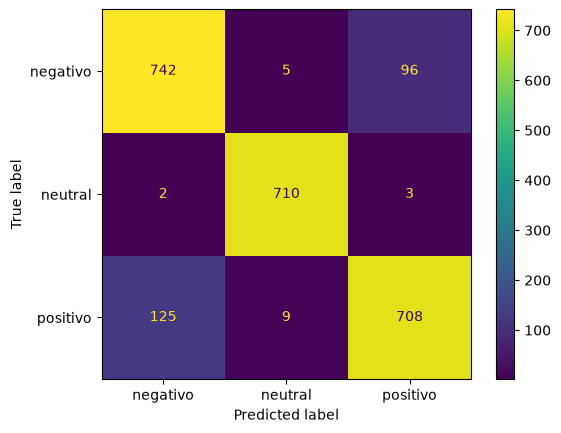

In [11]:
def predecir_hibrido(X, modelo, transform):
    """Predicción del modelo, reemplazada por la de la regla en las reseñas donde la regla aplica."""
    prediccion = pd.Series(modelo.predict(transform(X)), index=X.index)
    regla = predecir_con_regla(X["text"])
    return regla.where(regla.notna(), prediccion), regla.notna()


y_pred_hibrido, aplica_test = predecir_hibrido(X_test, voting_classifier, lambda X: X_test_transformed)
y_pred_voting = pd.Series(y_pred_voting, index=X_test.index)

print(f"La regla aplica a {aplica_test.sum()} reseñas del test ({aplica_test.mean():.1%})")
print(f"  En ellas: accuracy del modelo {accuracy_score(y_test[aplica_test], y_pred_voting[aplica_test]):.4f} "
      f"| accuracy de la regla {accuracy_score(y_test[aplica_test], y_pred_hibrido[aplica_test]):.4f}")
print(f"  Predicciones que cambian: {(y_pred_hibrido != y_pred_voting).sum()}")
print()
print(f"Accuracy Voting Classifier: {accuracy_score(y_test, y_pred_voting):.4f}")
print(f"Accuracy modelo híbrido:    {accuracy_score(y_test, y_pred_hibrido):.4f}")
print(classification_report(y_test, y_pred_hibrido))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_hibrido)
plt.show()

## Creación de la submission

In [12]:
eval_data = pd.read_csv("data/eval.csv")
y_pred_eval, aplica_eval = predecir_hibrido(eval_data, voting_classifier, preprocessor.transform)
print(f"La regla aplica a {aplica_eval.mean():.1%} de eval")

pd.DataFrame({"id": eval_data["id"], "answer": y_pred_eval}).to_csv("submission_hibrido_1.csv", index=False)

La regla aplica a 16.4% de eval
